# <center>Блок 6. Математика в ML. Часть II<center>
## <center>MATH&ML-11. Кластеризация и техника понижения размерности. Часть II<center>
### <center>1.Введение<center>
### <center>2.Оценка качества кластеризации: внутренние меры<center>
#### <center>Коэффициент силуэта<center>

In [1]:
#определяем алгоритм кластеризации
#km = KMeans(n_clusters=3, random_state=42)
#обучаем его на наших данных
#km.fit_predict(X)
#вычисляем значение коэффициента силуэта
#score = silhouette_score(X, km.labels_, metric='euclidean')

#### <center>Индекс Калински-Харабаса<center>

In [2]:
#определяем алгоритм кластеризации
#km = KMeans(n_clusters=3, random_state=42)
#обучаем его на наших данных
#km.fit_predict(X)
#вычисляем значение коэффициента Калински — Харабаса
#score = calinski_harabasz_score(X, km.labels_)

#### <center>Индекс Дэвиса-Болдина<center>

In [3]:
#определяем алгоритм кластеризации
#km = KMeans(n_clusters=3, random_state=42)
#обучаем его на наших данных
#km.fit_predict(X)
#вычисляем значение коэффициента Дэвиса — Болдина
#score = davies_bouldin_score(X, km.labels_)

#### <center>Внутрикластерное расстояние<center>
#### <center>Межкластерное расстояние<center>
#### <center>Отношение расстояний<center>
### <center>3.Оценка качества кластеризации: внешние меры<center>
#### <center>Индекс Рэнда<center>

In [4]:
#print(rand_score([1, 1, 1, 2, 2], [1, 1, 2, 2, 3]))

#### <center>Нормализованная взаимная информация<center>
#### <center>Однородность<center>
#### <center>Полнота<center>
#### <center>V-мера<center>
### <center>4.Меры качества класстеризации. Практика<center>

In [58]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score, homogeneity_score, completeness_score, adjusted_rand_score
from sklearn.cluster import KMeans, AgglomerativeClustering
import matplotlib.pyplot as plt

In [ ]:
# Задание 4.1

X_train = np.loadtxt("C:\\IDE\\data\\Block_6\\train.txt")
y_train = np.loadtxt("C:\\IDE\\data\\Block_6\\train_labels.txt")
 
X_test = np.loadtxt("C:\\IDE\\data\\Block_6\\test.txt")
y_test = np.loadtxt("C:\\IDE\\data\\Block_6\\test_labels.txt")
X = np.concatenate((X_train, X_test))
y = np.concatenate((y_train, y_test))
X.shape

(10299, 561)

In [29]:
# Задание 4.2

print(len(np.unique(y)))

6


In [34]:
# Задание 4.3

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(np.round(X_scaled[0][0],2))


0.21


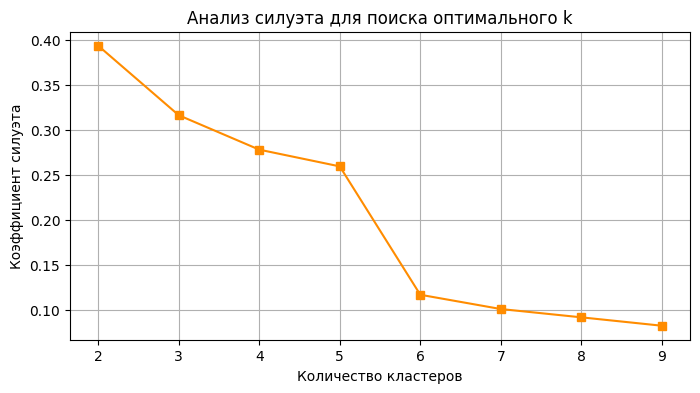

0.39


In [ ]:
# Задание 4.4(1)

def get_silhouette(cluster_num, X_scaled):
    kmeans = KMeans(init='k-means++', n_clusters=cluster_num, random_state=42)
    kmeans.fit(X_scaled)
    silhouette = silhouette_score(X_scaled, kmeans.labels_)
    return silhouette

silhouette = []
for cluster_num in range(2,10):
    silhouette.append(get_silhouette(cluster_num, X_scaled))
    
plt.figure(figsize=(8, 4))
plt.plot(range(2, 10), silhouette, marker='s', color='darkorange')
plt.title('Анализ силуэта для поиска оптимального k')
plt.xlabel('Количество кластеров')
plt.ylabel('Коэффициент силуэта')
plt.grid(True)
plt.show()

kmeans = KMeans(init='k-means++', n_clusters=2, random_state=42)
kmeans.fit(X_scaled)
silhouette = silhouette_score(X_scaled, kmeans.labels_)
print(np.round(silhouette,2))

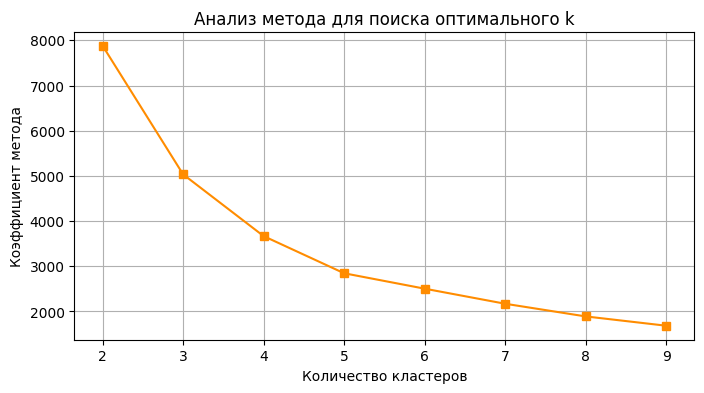

7880.81


In [44]:
# Задание 4.4(2)
def get_chs(cluster_num, X_scaled):
    kmeans = KMeans(init='k-means++', n_clusters=cluster_num, random_state=42)
    kmeans.fit(X_scaled)
    chs = calinski_harabasz_score(X_scaled, kmeans.labels_)
    return chs

chs = []
for cluster_num in range(2,10):
    chs.append(get_chs(cluster_num, X_scaled))
    
plt.figure(figsize=(8, 4))
plt.plot(range(2, 10), chs, marker='s', color='darkorange')
plt.title('Анализ метода для поиска оптимального k')
plt.xlabel('Количество кластеров')
plt.ylabel('Коэффициент метода')
plt.grid(True)
plt.show()

kmeans = KMeans(init='k-means++', n_clusters=2, random_state=42)
kmeans.fit(X_scaled)
chs = calinski_harabasz_score(X_scaled, kmeans.labels_)
print(np.round(chs,2))


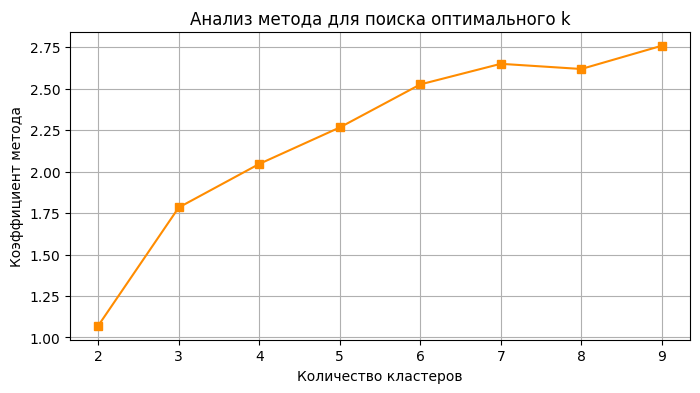

1.07


In [47]:
# Задание 4.4(3)

def get_dbs(cluster_num, X_scaled):
    kmeans = KMeans(init='k-means++', n_clusters=cluster_num, random_state=42)
    kmeans.fit(X_scaled)
    dbs = davies_bouldin_score(X_scaled, kmeans.labels_)
    return dbs

dbs = []
for cluster_num in range(2,10):
    dbs.append(get_dbs(cluster_num, X_scaled))
    
plt.figure(figsize=(8, 4))
plt.plot(range(2, 10), dbs, marker='s', color='darkorange')
plt.title('Анализ метода для поиска оптимального k')
plt.xlabel('Количество кластеров')
plt.ylabel('Коэффициент метода')
plt.grid(True)
plt.show()

kmeans = KMeans(init='k-means++', n_clusters=2, random_state=42)
kmeans.fit(X_scaled)
dbs = davies_bouldin_score(X_scaled, kmeans.labels_)
print(np.round(dbs,2))

In [51]:
# Задание 4.5

kmeans = KMeans(init='random', n_clusters=6, random_state=42)
kmeans.fit(X_scaled)
print(np.round(homogeneity_score(y, kmeans.labels_),2))
print(np.round(completeness_score(y, kmeans.labels_),2))
print(np.round(adjusted_rand_score(y, kmeans.labels_),2))

0.54
0.58
0.42


In [52]:
# Задание 4.6

# 1. Корректируем нумерацию кластеров, чтобы она начиналась с 1
cluster_labels_1based = kmeans.labels_ + 1

# 2. Строим таблицу сопряженности (crosstab)
# Преобразуем y и cluster_labels в Series, чтобы задать красивые имена осям
ct = pd.crosstab(
    index=pd.Series(y, name='Активность'), 
    columns=pd.Series(cluster_labels_1based, name='Кластер')
)

# Отображаем получившуюся таблицу
print("Таблица сопряженности (Crosstab):")
print(ct)
print("\n" + "="*50 + "\n")

# 3. Автоматически определяем, в какой кластер попало большинство наблюдений для каждой активности
print("Преимущественный кластер для каждой активности:")
for activity in ct.index:
    # Находим номер кластера с максимальным количеством совпадений для данной активности
    dominant_cluster = ct.loc[activity].idxmax()
    count = ct.loc[activity].max()
    print(f"Активность {activity} -> преимущественно в Кластере {dominant_cluster} (количество: {count})")

Таблица сопряженности (Crosstab):
Кластер       1     2    3     4    5     6
Активность                                 
1.0         741   897    0     0   84     0
2.0         297  1236    2     0    9     0
3.0         882   310    0     0  214     0
4.0           0     1  447    91    0  1238
5.0           0     0  560     0    0  1346
6.0           0     5  329  1556    0    54


Преимущественный кластер для каждой активности:
Активность 1.0 -> преимущественно в Кластере 2 (количество: 897)
Активность 2.0 -> преимущественно в Кластере 2 (количество: 1236)
Активность 3.0 -> преимущественно в Кластере 1 (количество: 882)
Активность 4.0 -> преимущественно в Кластере 6 (количество: 1238)
Активность 5.0 -> преимущественно в Кластере 6 (количество: 1346)
Активность 6.0 -> преимущественно в Кластере 4 (количество: 1556)


In [56]:
# Задание 4.7

kmeans = KMeans(init='random', n_clusters=2, random_state=42)
kmeans.fit(X_scaled)

# 1. Корректируем нумерацию кластеров, чтобы она начиналась с 1
cluster_labels_1based = kmeans.labels_ + 1

# 2. Строим таблицу сопряженности (crosstab)
# Преобразуем y и cluster_labels в Series, чтобы задать красивые имена осям
ct = pd.crosstab(
    index=pd.Series(y, name='Активность'), 
    columns=pd.Series(cluster_labels_1based, name='Кластер')
)

# Отображаем получившуюся таблицу
print("Таблица сопряженности (Crosstab):")
print(ct)
print("\n" + "="*50 + "\n")

# 3. Автоматически определяем, в какой кластер попало большинство наблюдений для каждой активности
print("Преимущественный кластер для каждой активности:")
for activity in ct.index:
    # Находим номер кластера с максимальным количеством совпадений для данной активности
    dominant_cluster = ct.loc[activity].idxmax()
    count = ct.loc[activity].max()
    print(f"Активность {activity} -> преимущественно в Кластере {dominant_cluster} (количество: {count})")

Таблица сопряженности (Crosstab):
Кластер        1     2
Активность            
1.0         1722     0
2.0         1536     8
3.0         1406     0
4.0            3  1774
5.0            0  1906
6.0           12  1932


Преимущественный кластер для каждой активности:
Активность 1.0 -> преимущественно в Кластере 1 (количество: 1722)
Активность 2.0 -> преимущественно в Кластере 1 (количество: 1536)
Активность 3.0 -> преимущественно в Кластере 1 (количество: 1406)
Активность 4.0 -> преимущественно в Кластере 2 (количество: 1774)
Активность 5.0 -> преимущественно в Кластере 2 (количество: 1906)
Активность 6.0 -> преимущественно в Кластере 2 (количество: 1932)


In [57]:
# Задание 4.8

print(np.round(completeness_score(y, kmeans.labels_),2))

0.98


In [59]:
# Задание 4.10

agg_clustering = AgglomerativeClustering(n_clusters=2)
agg_clustering.fit_predict(X_scaled)

print(np.round(completeness_score(y, agg_clustering.labels_),2))

1.0


### <center>5.PCA<center>